# ITCS 6169/8169 — Assignment 3: choosing *which* labeled image to use for each class

With one labeled image per class, which image you pick matters a lot: across five random support sets the prototype-only accuracy ranged over
about 15 points, and a Forest photo with a single tree sank two of them. This notebook asks whether a better choice of the 16 images can be found,
and measures how much of any gain is real.

**Setup.** A *candidate pool* of `POOL_PER_CLASS` training images per class is drawn at random with a seeded generator (nothing is hand-picked).
Exactly one image per class ends up in the final classifier. Four ways of choosing it, all declared before any result is seen:

| | Strategy | Uses test labels? |
|---|---|---|
| S1 | **typical**: the candidate closest on average to the other candidates of its class | no |
| S2 | **text-agreement**: the candidate its own class prompt describes best (zero-shot z-score of its class) | no |
| S3 | **typical + text**: sum of the two within-class z-scores | no |
| S4 | **test-label search**: coordinate ascent over all 16 choices to maximise the blend's accuracy | **yes** |
| baseline | random picks from the same pool (`N_RANDOM` draws): the distribution to beat | no |

**How the test-label search is kept honest.** The test images are split once into two class-balanced halves (seeded, before any search). The search
runs on one half and is scored on the *other*, in both directions (2-fold cross-fitting). That held-out accuracy, compared with random picks on the same
half, is the honest estimate of what the *search procedure* buys. The combination finally saved (searched on all 400 test images) is scored on those same
images, so its full-test accuracy is **optimistic**, and the notebook labels it that way.

**Rules.**
- The assignment says it is "strictly forbidden to use more than one training sample per-class". Building a pool means embedding and scoring `POOL_PER_CLASS`
  candidates per class to *choose* one, even though only one per class is used in the final classifier. Whether that is allowed is the instructor's call.
  **Ask before relying on this notebook, and disclose it in the report.**
- Test labels are used to score methods, and in S4 to choose images. Say so explicitly if you report S4.
- S1 to S3 and the random baseline never look at test labels (the test set is only the yardstick).

**Needs:** the zero-shot and one-shot notebooks run first (this notebook reuses their test-image and text caches), plus `transformers` for embedding the
pool and the final images (an estimated few minutes for SigLIP base on CPU; the larger models take much longer). Everything is cached in `a3_cache/`.

In [1]:
# Core imports
import os, sys, gc, json, csv, time, math, random, warnings
from pathlib import Path

os.environ.setdefault('HF_HUB_DISABLE_SYMLINKS_WARNING', '1')     # Windows: silence the symlink notice

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn.functional as F
from torchvision import datasets

try:
    import torch_directml  # AMD GPU on Windows (optional)
    HAS_DML = torch_directml.is_available()
except ImportError:
    HAS_DML = False

try:
    import transformers
    from transformers import AutoModel, AutoProcessor, AutoImageProcessor
except ImportError as e:
    raise ImportError('This notebook needs Hugging Face transformers. In your venv run:\n'
                      '    pip install "transformers>=4.49,<5" sentencepiece protobuf') from e

print('PyTorch        :', torch.__version__)
print('transformers   :', transformers.__version__)
print('CUDA available :', torch.cuda.is_available())
print('DirectML       :', HAS_DML)
print('CPU threads    :', torch.get_num_threads())

d:\School\13 - Fall 2026\ITCS 6169\assignment3\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch        : 2.15.0+cpu
transformers   : 4.57.6
CUDA available : False
DirectML       : False
CPU threads    : 8


## Paths and device

In [2]:
PROJECT_ROOT = Path('.')                       # run the notebook from your project folder
TRAIN_ROOT   = PROJECT_ROOT / 'data' / 'train'
TEST_ROOT    = PROJECT_ROOT / 'data' / 'test'
CACHE_DIR    = PROJECT_ROOT / 'a3_cache'       # embeddings are cached here, so a crash or re-run resumes quickly
RESULTS_DIR  = PROJECT_ROOT / 'a3_results'
CACHE_DIR.mkdir(exist_ok=True); RESULTS_DIR.mkdir(exist_ok=True)

EXPECTED_CLASSES = ['Bedroom', 'Coast', 'Flower', 'Forest', 'Highway', 'Industrial', 'InsideCity', 'Kitchen',
                    'LivingRoom', 'Mountain', 'Office', 'OpenCountry', 'Store', 'Street', 'Suburb', 'TallBuilding']
NUM_CLASSES = len(EXPECTED_CLASSES)
print('Project root:', PROJECT_ROOT.resolve())

Project root: D:\School\13 - Fall 2026\ITCS 6169\assignment3


In [3]:
# Inference on CPU is the default: only a few hundred images are embedded, and CPU is the safe choice
# (DirectML has needed workarounds in earlier assignments). Set USE_GPU = True to try the GPU; every model
# is then checked against the CPU embeddings first and falls back to CPU if they disagree.
USE_GPU = False
BATCH_SIZE = 8              # lower this if a large model runs out of memory

def pick_device():
    if not USE_GPU:
        return torch.device('cpu')
    if torch.cuda.is_available():
        return torch.device('cuda')
    if HAS_DML:
        return torch_directml.device()
    return torch.device('cpu')

DEVICE = pick_device()
print('Device:', DEVICE)

Device: cpu


## Configuration (declared in advance)
`SELECT_MODEL` is the model used for the pool, the search and the final scoring; its test-image and text caches must already exist
(zero-shot or one-shot notebook). The pool is embedded with the original view only; the final combinations are re-embedded with `N_AUG` augmented
views, exactly as in the one-shot notebook.

In [4]:
MODEL_SPECS = {
    'clip-b16':           dict(kind='clip',   repo='openai/clip-vit-base-patch16'),
    'clip-l14':           dict(kind='clip',   repo='openai/clip-vit-large-patch14'),
    'siglip-b16-224':     dict(kind='siglip', repo='google/siglip-base-patch16-224'),
    'siglip-so400m-384':  dict(kind='siglip', repo='google/siglip-so400m-patch14-384'),
}
SELECT_MODEL   = 'siglip-b16-224'        # the model used for everything from here on (best zero-shot and one-shot mean in the earlier notebooks)

POOL_PER_CLASS = 20          # candidate training images per class
POOL_SEED      = 5000        # seeded draw of the pool
SPLIT_SEED     = 2024        # seeded class-balanced split of the test images into two halves
N_RANDOM       = 500         # random combinations for the baseline distribution
N_RESTARTS     = 20          # random restarts of the coordinate-ascent search
MAX_SWEEPS     = 10
N_AUG          = 8           # augmented views per selected image in the final evaluation (as in the one-shot notebook)
SEL_AUG_SEED   = 90          # seed of those augmentations

BLEND_ALPHA    = 0.5         # same blend as the one-shot notebook (text weight)
AUG_EVAL       = ['S1', 'S2', 'S3', 'S4']       # which combinations get the final augmented evaluation (each costs 16 x (1 + N_AUG) embeddings)

assert MODEL_SPECS[SELECT_MODEL]['kind'] in ('clip', 'siglip'), 'selection needs a text side: use a CLIP or SigLIP model'
print('select model:', SELECT_MODEL, '| pool', POOL_PER_CLASS, 'per class')

select model: siglip-b16-224 | pool 20 per class


In [5]:
# ---- analysis helpers (numpy only) ----
def l2norm(x, axis=-1):
    return x / (np.linalg.norm(x, axis=axis, keepdims=True) + 1e-12)

def accuracy(pred, y):
    return float((np.asarray(pred) == np.asarray(y)).mean())

def binomial_se(p, n):
    return math.sqrt(max(p * (1 - p), 0.0) / n)

def per_class_accuracy(pred, y, num_classes):
    pred, y = np.asarray(pred), np.asarray(y)
    return [float((pred[y == c] == c).mean()) if (y == c).any() else float('nan') for c in range(num_classes)]

def confusion_matrix(pred, y, num_classes):
    cm = np.zeros((num_classes, num_classes), dtype=int)
    np.add.at(cm, (np.asarray(y), np.asarray(pred)), 1)          # rows = true class, columns = predicted class
    return cm

def top_confusions(cm, names, k=6):
    off = [(int(cm[i, j]), names[i], names[j]) for i in range(len(names)) for j in range(len(names)) if i != j and cm[i, j] > 0]
    return sorted(off, reverse=True)[:k]

def zscore_rows(s):
    """Standardise each row (one test image) across the classes, so two score types can be added fairly."""
    return (s - s.mean(1, keepdims=True)) / (s.std(1, keepdims=True) + 1e-8)

def make_prototypes(view_embs, mode):
    """view_embs: [classes, views, dim], every view L2-normalised, view 0 = the original image.
    'noaug' = the original image only; 'aug' = mean over the original and its augmented views."""
    p = view_embs[:, 0] if mode == 'noaug' else view_embs.mean(1)
    return l2norm(p)

def mean_std(values):
    v = np.asarray(values, dtype=float)
    return float(v.mean()), (float(v.std(ddof=1)) if len(v) > 1 else float('nan'))

In [6]:
# ---- small on-disk cache for embeddings (numpy only) ----
def cached_npz(path, build_fn, check=None):
    """Load {name: array} from `path` if it exists and passes `check`, otherwise build it and save it."""
    path = Path(path)
    if path.exists():
        try:
            with np.load(path, allow_pickle=False) as z:
                data = {k: z[k] for k in z.files}
            if check is None or check(data):
                return data
            print(f'  cache {path.name} is stale -> recomputing')
        except Exception as e:
            print(f'  cache {path.name} unreadable ({e}) -> recomputing')
    data = build_fn()
    np.savez_compressed(path, **data)
    return data

In [7]:
# ---- model loading and embedding (Hugging Face transformers) ----
def _unwrap(x):
    """get_*_features returns a tensor in transformers 4.x; be tolerant of output objects."""
    if torch.is_tensor(x):
        return x
    for attr in ('image_embeds', 'text_embeds', 'pooler_output'):
        v = getattr(x, attr, None)
        if v is not None:
            return v
    raise TypeError(f'unexpected feature output type: {type(x)}')

def load_bundle(key):
    spec = MODEL_SPECS[key]
    t0 = time.time()
    model = AutoModel.from_pretrained(spec['repo']).eval()
    for p in model.parameters():
        p.requires_grad_(False)
    proc = AutoImageProcessor.from_pretrained(spec['repo']) if spec['kind'] == 'dino' else AutoProcessor.from_pretrained(spec['repo'])
    n_params = sum(p.numel() for p in model.parameters()) / 1e6
    print(f"loaded {key}  ({spec['repo']}, {n_params:.0f}M parameters, {time.time() - t0:.0f}s)")
    return dict(key=key, kind=spec['kind'], model=model, proc=proc)

@torch.no_grad()
def embed_images(bundle, images, device, batch_size=8, quiet=False):
    """Returns {variant: array[N, D]} of L2-normalised embeddings.
    CLIP / SigLIP -> {'img'};  DINOv2 -> {'cls', 'patch', 'cls_patch'}."""
    model, kind, proc = bundle['model'].to(device), bundle['kind'], bundle['proc']
    chunks, t0, n_batches = {}, time.time(), math.ceil(len(images) / batch_size)
    for bi, i in enumerate(range(0, len(images), batch_size)):
        inputs = proc(images=images[i:i + batch_size], return_tensors='pt')
        inputs = {k: v.to(device) for k, v in inputs.items()}
        if kind == 'dino':
            h = model(pixel_values=inputs['pixel_values']).last_hidden_state.float()
            c, p = F.normalize(h[:, 0], dim=-1), F.normalize(h[:, 1:].mean(1), dim=-1)
            feats = {'cls': c, 'patch': p, 'cls_patch': F.normalize(torch.cat([c, p], dim=-1), dim=-1)}
        else:
            feats = {'img': F.normalize(_unwrap(model.get_image_features(**inputs)).float(), dim=-1)}
        for k, v in feats.items():
            chunks.setdefault(k, []).append(v.cpu())
        if not quiet and (bi == 1 or (bi + 1) % max(1, n_batches // 5) == 0 or bi + 1 == n_batches):
            el = time.time() - t0
            done = min(i + batch_size, len(images))
            print(f'    {done}/{len(images)} images | {el:.0f}s elapsed | projected total {el / done * len(images):.0f}s')
    return {k: torch.cat(v).numpy() for k, v in chunks.items()}

@torch.no_grad()
def embed_texts(bundle, texts, device, batch_size=64):
    """L2-normalised text embeddings [N, D] for CLIP / SigLIP models."""
    model, kind, proc = bundle['model'].to(device), bundle['kind'], bundle['proc']
    out = []
    for i in range(0, len(texts), batch_size):
        chunk = texts[i:i + batch_size]
        if kind == 'siglip':       # SigLIP models were trained on lower-case text padded to 64 tokens, without a mask
            tok = proc(text=[t.lower() for t in chunk], padding='max_length', max_length=64, truncation=True, return_tensors='pt')
            f = model.get_text_features(input_ids=tok['input_ids'].to(device))
        else:                      # CLIP
            tok = proc(text=chunk, padding=True, truncation=True, max_length=77, return_tensors='pt')
            f = model.get_text_features(input_ids=tok['input_ids'].to(device), attention_mask=tok['attention_mask'].to(device))
        out.append(F.normalize(_unwrap(f).float(), dim=-1).cpu())
    return torch.cat(out).numpy()

def choose_run_device(bundle, sample_images):
    """CPU unless USE_GPU is on and the GPU embeddings match the CPU ones (cosine > 0.999 on a few images)."""
    if DEVICE.type == 'cpu':
        return DEVICE
    cpu = torch.device('cpu')
    a = embed_images(bundle, sample_images, cpu, 4, quiet=True)
    b = embed_images(bundle, sample_images, DEVICE, 4, quiet=True)
    k = next(iter(a))
    min_cos = float((a[k] * b[k]).sum(1).min())
    if min_cos > 0.999:
        print(f'  GPU check passed (min cosine vs CPU = {min_cos:.5f}) -> using {DEVICE}')
        return DEVICE
    print(f'  GPU check FAILED (min cosine vs CPU = {min_cos:.4f}) -> falling back to CPU')
    bundle['model'].to(cpu)
    return cpu

## Test and text embeddings (from the earlier notebooks) and the two test halves

In [8]:
def first_existing(candidates):
    for path, key in candidates:
        if path.exists():
            with np.load(path, allow_pickle=False) as z:
                return z[key]
    raise FileNotFoundError('missing cache (run the zero-shot / one-shot notebook first): ' + ', '.join(p.name for p, _ in candidates))

with np.load(CACHE_DIR / f'test_{SELECT_MODEL}.npz', allow_pickle=False) as z:
    X, test_labels = z['img'], z['labels']
T = first_existing([(CACHE_DIR / f'os_{SELECT_MODEL}_text.npz', 'emb'), (CACHE_DIR / f'zs_{SELECT_MODEL}_text.npz', 'descriptive__ensemble')])
assert T.shape == (NUM_CLASSES, X.shape[1])

def stratified_halves(labels, seed):
    rng = np.random.default_rng(seed)
    A, B = [], []
    for c in range(NUM_CLASSES):
        idx = rng.permutation(np.where(labels == c)[0])
        h = (len(idx) + 1) // 2
        A += idx[:h].tolist(); B += idx[h:].tolist()
    return np.array(sorted(A)), np.array(sorted(B))

HALF_A, HALF_B = stratified_halves(test_labels, SPLIT_SEED)
ALL = np.arange(len(test_labels))
print(f'{len(ALL)} test images | half A {len(HALF_A)}, half B {len(HALF_B)} | zero-shot text accuracy {accuracy((X @ T.T).argmax(1), test_labels):.4f}')

400 test images | half A 208, half B 192 | zero-shot text accuracy 0.8925


## The candidate pool
`POOL_PER_CLASS` images per class, drawn at random from the file listing. Only these pool images are opened. Embedded once with the original view only.

In [9]:
IMG_EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.webp', '.tif', '.tiff'}

def list_class_images(cls):
    return sorted(p for p in (TRAIN_ROOT / cls).iterdir() if p.suffix.lower() in IMG_EXT)

def load_rgb(p):
    with Image.open(p) as im:
        return im.convert('RGB')

rng_pool = np.random.default_rng(POOL_SEED)
pool_paths = []
for c in EXPECTED_CLASSES:
    files = list_class_images(c)
    pick = np.sort(rng_pool.choice(len(files), size=POOL_PER_CLASS, replace=False))
    pool_paths.append([files[i] for i in pick])
pool_names = np.array([[str(p) for p in row] for row in pool_paths])
K = POOL_PER_CLASS

state = {}
def get_bundle():
    if 'b' not in state:
        state['b'] = load_bundle(SELECT_MODEL)
        state['dev'] = choose_run_device(state['b'], [load_rgb(pool_paths[0][0])] * 4)
    return state['b'], state['dev']

def build_pool():
    b, dev = get_bundle()
    imgs = [load_rgb(p) for row in pool_paths for p in row]
    d = embed_images(b, imgs, dev, BATCH_SIZE)
    return dict(img=d['img'].reshape(NUM_CLASSES, K, -1), paths=pool_names)

pool = cached_npz(CACHE_DIR / f'pool_{SELECT_MODEL}_n{K}_s{POOL_SEED}.npz', build_pool,
                  check=lambda d: d['paths'].shape == pool_names.shape and bool((d['paths'] == pool_names).all()))
E = pool['img']                                            # [classes, candidates, dim]
print('pool embeddings:', E.shape)

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


loaded siglip-b16-224  (google/siglip-base-patch16-224, 203M parameters, 1s)
    16/320 images | 3s elapsed | projected total 53s
    64/320 images | 7s elapsed | projected total 36s
    128/320 images | 13s elapsed | projected total 33s
    192/320 images | 19s elapsed | projected total 32s
    256/320 images | 25s elapsed | projected total 31s
    320/320 images | 31s elapsed | projected total 31s
pool embeddings: (16, 20, 768)


## Scoring a combination
A combination is one candidate index per class (`j`, length 16). Its prototypes are the candidates' embeddings; the classifier is the same score blend as in the
one-shot notebook (z-scored text scores and prototype scores, `BLEND_ALPHA`). Because the pool is embedded once, evaluating a combination is just indexing.

In [10]:
def softmax_rows(z):
    z = z - z.max(1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(1, keepdims=True)

AR = np.arange(NUM_CLASSES)
Zt = zscore_rows(X @ T.T)                                  # text scores, z-scored per image
SIMP = np.einsum('nd,ckd->nck', X, E)                      # [images, classes, candidates]: similarity of every test image to every candidate

def combo_scores(rows, j, method='blend'):
    Sp = SIMP[rows][:, AR, j]
    return Sp if method == 'proto' else BLEND_ALPHA * Zt[rows] + (1 - BLEND_ALPHA) * zscore_rows(Sp)

def combo_acc(rows, j, method='blend'):
    return accuracy(combo_scores(rows, j, method).argmax(1), test_labels[rows])

## Baseline: random picks from the same pool
`N_RANDOM` random combinations. This is the distribution that any selection strategy has to beat, evaluated on all 400 test images and on each half.

In [11]:
rng_rand = np.random.default_rng(POOL_SEED + 1)
rand_j = rng_rand.integers(0, K, size=(N_RANDOM, NUM_CLASSES))
rand = {m: {nm: np.array([combo_acc(rows, j, m) for j in rand_j]) for nm, rows in (('all', ALL), ('A', HALF_A), ('B', HALF_B))} for m in ('blend', 'proto')}
for m in ('proto', 'blend'):
    r = rand[m]['all']
    print(f'random combinations, {m:<5} (original-view prototypes): mean {r.mean():.4f} | std {r.std(ddof=1):.4f} | 5th-95th percentile {np.percentile(r, 5):.4f} to {np.percentile(r, 95):.4f} | best {r.max():.4f}')
print(f"\nzero-shot text alone for reference: {accuracy((X @ T.T).argmax(1), test_labels):.4f}")

random combinations, proto (original-view prototypes): mean 0.7683 | std 0.0455 | 5th-95th percentile 0.6875 to 0.8425 | best 0.8700
random combinations, blend (original-view prototypes): mean 0.9004 | std 0.0173 | 5th-95th percentile 0.8725 to 0.9301 | best 0.9475

zero-shot text alone for reference: 0.8925


## S1 to S3: label-free selection
None of these uses a test label, so they cannot overfit to the test set; each is evaluated once.

In [12]:
def zs1(v):
    return (v - v.mean()) / (v.std() + 1e-8)

typ = np.zeros((NUM_CLASSES, K)); txt = np.zeros((NUM_CLASSES, K))
for c in range(NUM_CLASSES):
    G = E[c] @ E[c].T
    typ[c] = (G.sum(1) - np.diag(G)) / (K - 1)                # mean cosine to the other candidates of the same class
    txt[c] = zscore_rows(E[c] @ T.T)[:, c]                    # how strongly the class prompt picks this candidate over the other 15 classes
combos = {'S1': typ.argmax(1), 'S2': txt.argmax(1), 'S3': np.array([(zs1(typ[c]) + zs1(txt[c])).argmax() for c in range(NUM_CLASSES)])}

def pct(m, a):
    return float((rand[m]['all'] < a).mean() * 100)

print(f"{'strategy':<10}{'proto acc':>11}{'blend acc':>11}{'percentile of random (blend)':>31}")
print(f"{'random':<10}{rand['proto']['all'].mean():>11.4f}{rand['blend']['all'].mean():>11.4f}{'50 (by construction)':>31}")
for n in ('S1', 'S2', 'S3'):
    j = combos[n]
    print(f"{n:<10}{combo_acc(ALL, j, 'proto'):>11.4f}{combo_acc(ALL, j, 'blend'):>11.4f}{pct('blend', combo_acc(ALL, j, 'blend')):>31.0f}")
print('\nthe test set was used only to score these, never to choose them.')

strategy    proto acc  blend acc   percentile of random (blend)
random         0.7683     0.9004           50 (by construction)
S1             0.9000     0.9350                             97
S2             0.8550     0.8975                             42
S3             0.8725     0.9175                             81

the test set was used only to score these, never to choose them.


## S4: test-label search, with cross-fitting
Coordinate ascent: start from a random combination, change one class's image at a time to whichever candidate maximises the objective on the **search set**
(accuracy of the blend, with a tiny tie-breaker on the true-class probability), sweep the classes until nothing improves, and keep the best of
`N_RESTARTS` restarts. Run once per direction (search on A, score on B; search on B, score on A) and once on all 400 images for the combination that is saved.

In [13]:
def search(rows, n_restarts, seed):
    Sp, Zr, y = SIMP[rows], Zt[rows], test_labels[rows]
    ar_n = np.arange(len(y))
    rng = np.random.default_rng(seed)
    def obj(j):
        S = BLEND_ALPHA * Zr + (1 - BLEND_ALPHA) * zscore_rows(Sp[:, AR, j])
        q = softmax_rows(zscore_rows(S) * 2.0)
        return accuracy(S.argmax(1), y) + 1e-3 * float(q[ar_n, y].mean())
    best_j, best_o = None, -1.0
    for _ in range(n_restarts):
        j = rng.integers(0, K, size=NUM_CLASSES)
        cur = obj(j)
        for _sweep in range(MAX_SWEEPS):
            changed = False
            for c in rng.permutation(NUM_CLASSES):
                best_k, best_v = j[c], cur
                for k in range(K):
                    if k == j[c]:
                        continue
                    j2 = j.copy(); j2[c] = k
                    v = obj(j2)
                    if v > best_v + 1e-12:
                        best_k, best_v = k, v
                if best_k != j[c]:
                    j[c], cur, changed = best_k, best_v, True
            if not changed:
                break
        if cur > best_o:
            best_j, best_o = j.copy(), cur
    return best_j

t0 = time.time()
folds = {}
for name, (tr, te) in {'search A -> held-out B': (HALF_A, HALF_B), 'search B -> held-out A': (HALF_B, HALF_A)}.items():
    j = search(tr, N_RESTARTS, seed=POOL_SEED + 10)
    key_te = 'B' if te is HALF_B else 'A'
    folds[name] = dict(j=j, search_acc=combo_acc(tr, j), heldout_acc=combo_acc(te, j), random_heldout=float(rand['blend'][key_te].mean()),
                       random_search=float(rand['blend']['A' if tr is HALF_A else 'B'].mean()))
j_final = search(ALL, N_RESTARTS, seed=POOL_SEED + 11)
combos['S4'] = j_final
print(f'searches done in {time.time() - t0:.0f}s\n')
print(f"{'fold':<26}{'on search half':>16}{'on held-out half':>18}{'random, held-out':>18}{'gain on held-out':>18}")
for name, f in folds.items():
    print(f"{name:<26}{f['search_acc']:>16.4f}{f['heldout_acc']:>18.4f}{f['random_heldout']:>18.4f}{f['heldout_acc'] - f['random_heldout']:>+18.4f}")
ho = np.mean([f['heldout_acc'] for f in folds.values()]); rh = np.mean([f['random_heldout'] for f in folds.values()]); sa = np.mean([f['search_acc'] for f in folds.values()])
print(f"\nhonest estimate of the search procedure: held-out {ho:.4f} vs random {rh:.4f} -> gain {ho - rh:+.4f}   (search-half accuracy {sa:.4f}, the optimism is {sa - ho:+.4f})")
print(f"S4 final combination (searched on all {len(ALL)} test images): {combo_acc(ALL, j_final):.4f}  <- OPTIMISTIC, chosen on the same images it is scored on")
print(f"each half has about {len(HALF_A)} images, so one held-out number is uncertain by about ±{binomial_se(0.9, len(HALF_A)) * 100:.1f} points")

searches done in 12s

fold                        on search half  on held-out half  random, held-out  gain on held-out
search A -> held-out B              0.9856            0.9323            0.8943           +0.0380
search B -> held-out A              0.9844            0.9519            0.9060           +0.0459

honest estimate of the search procedure: held-out 0.9421 vs random 0.9001 -> gain +0.0420   (search-half accuracy 0.9850, the optimism is +0.0429)
S4 final combination (searched on all 400 test images): 0.9775  <- OPTIMISTIC, chosen on the same images it is scored on
each half has about 208 images, so one held-out number is uncertain by about ±2.1 points


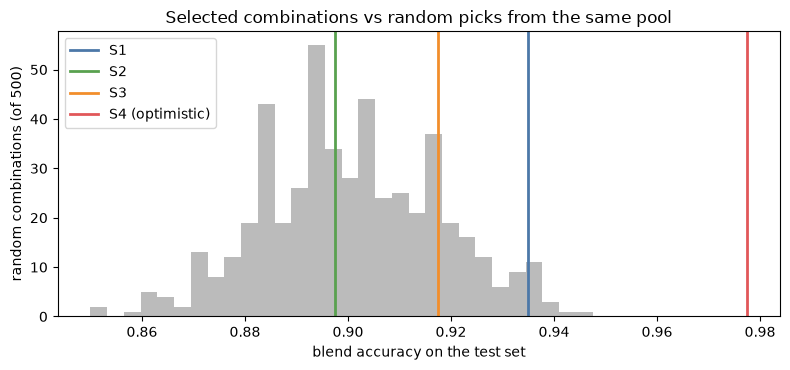

In [14]:
# How the strategies compare with the random distribution (blend accuracy on all 400 images; S4 is optimistic)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hist(rand['blend']['all'], bins=30, color='#bbb')
for n, col in (('S1', '#4c78a8'), ('S2', '#59a14f'), ('S3', '#f28e2b'), ('S4', '#e15759')):
    ax.axvline(combo_acc(ALL, combos[n]), color=col, label=n + (' (optimistic)' if n == 'S4' else ''), lw=2)
ax.set_xlabel('blend accuracy on the test set'); ax.set_ylabel(f'random combinations (of {N_RANDOM})'); ax.legend(); ax.set_title('Selected combinations vs random picks from the same pool')
plt.tight_layout(); plt.savefig(RESULTS_DIR / 'select_vs_random.png', dpi=150); plt.show()

## The chosen images
Look at them: it is the quickest way to see what a good (or overfitted) choice looks like. Viewing the *selected* images is fine; the rest of the pool does not need to be inspected.

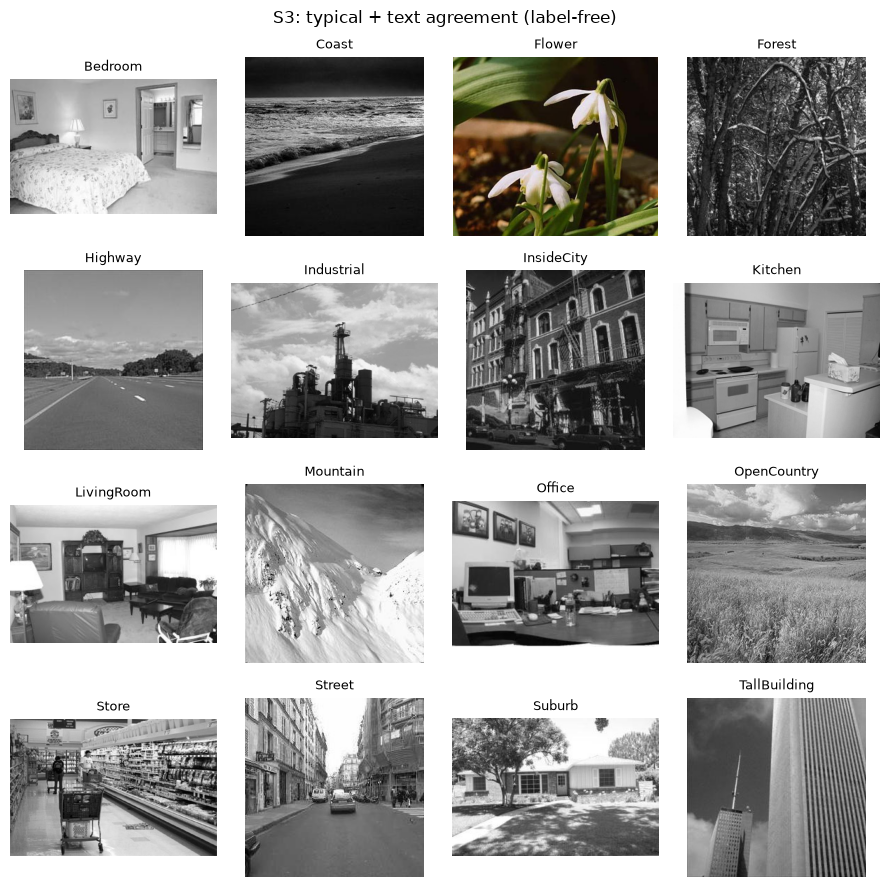

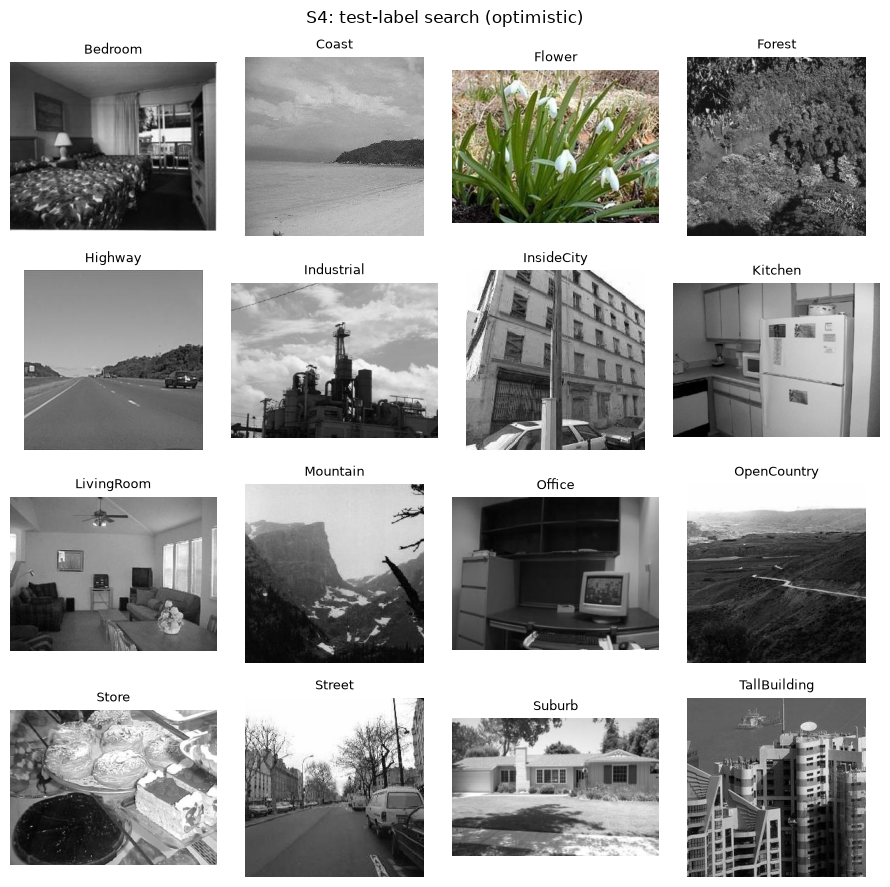

In [15]:
def show_grid(name, j, fname):
    fig, axes = plt.subplots(4, 4, figsize=(9, 9))
    for ax, c, cname in zip(axes.ravel(), range(NUM_CLASSES), EXPECTED_CLASSES):
        ax.imshow(load_rgb(pool_paths[c][int(j[c])])); ax.set_title(cname, fontsize=9); ax.axis('off')
    fig.suptitle(name); plt.tight_layout(); plt.savefig(RESULTS_DIR / fname, dpi=110); plt.show()

show_grid('S3: typical + text agreement (label-free)', combos['S3'], 'select_grid_S3.png')
show_grid('S4: test-label search (optimistic)', combos['S4'], 'select_grid_S4.png')

## Final evaluation of the chosen combinations
Each selected image is re-embedded with the original view plus `N_AUG` augmented views (as in the one-shot notebook), and scored with the prototype-only classifier
and the score blend. Compare with the random support sets from the one-shot notebook. S4 numbers are optimistic. This step loads the model again; embeddings are cached per combination.

In [16]:
import torchvision.transforms as TV

def make_views(path, seed, class_index, n_aug):
    img = load_rgb(path)
    W, H = img.size
    aug = TV.Compose([TV.RandomResizedCrop(size=(H, W), scale=(0.6, 1.0), ratio=(0.75, 4 / 3)),
                      TV.RandomHorizontalFlip(0.5),
                      TV.ColorJitter(brightness=0.2, contrast=0.2)])
    saved = torch.get_rng_state()
    torch.manual_seed(100_000 * seed + class_index)
    views = [img] + [aug(img) for _ in range(n_aug)]
    torch.set_rng_state(saved)
    return views

def views_for(name, j):
    paths = [pool_paths[c][int(j[c])] for c in range(NUM_CLASSES)]
    names = np.array([str(p) for p in paths])
    def build():
        b, dev = get_bundle()
        flat = [im for c, p in enumerate(paths) for im in make_views(p, SEL_AUG_SEED, c, N_AUG)]
        d = embed_images(b, flat, dev, BATCH_SIZE, quiet=True)
        return dict(img=d['img'].reshape(NUM_CLASSES, 1 + N_AUG, -1), paths=names)
    return cached_npz(CACHE_DIR / f'sel_{SELECT_MODEL}_{name}_aug{N_AUG}.npz', build,
                      check=lambda d: bool((d['paths'] == names).all()) and d['img'].shape[1] == 1 + N_AUG)['img']

In [17]:
final = {}
for n in AUG_EVAL:
    P = make_prototypes(views_for(n, combos[n]), 'aug')
    S2 = BLEND_ALPHA * Zt + (1 - BLEND_ALPHA) * zscore_rows(X @ P.T)
    final[n] = dict(M1=accuracy((X @ P.T).argmax(1), test_labels), M2=accuracy(S2.argmax(1), test_labels))
state.clear(); gc.collect()

ref = {}
try:
    js = json.loads((RESULTS_DIR / 'oneshot_results.json').read_text())
    ref['M1'] = [r['acc'] for r in js['rows'] if r['model'] == SELECT_MODEL and r['variant'] == 'img' and r['proto'] == 'aug']
    ref['M2'] = [r['acc'] for r in js['blend_rows'] if r['text_model'] == SELECT_MODEL and r['proto_model'] == SELECT_MODEL]
except Exception:
    pass
label = {'M1': 'prototype only', 'M2': 'score blend'}
print(f"{'':<8}{'combination':<28}" + ''.join(f'{label[m]:>16}' for m in ('M1', 'M2')))
if ref:
    print(f"{'random':<8}{'support sets from earlier notebooks':<28}" + ''.join(
        (f'{np.mean(ref[m]):>9.4f} ± {np.std(ref[m], ddof=1):.3f}' if m in ref and len(ref[m]) > 1 else f"{'n/a':>16}") for m in ('M1', 'M2')))
for n in AUG_EVAL:
    tag = {'S1': 'typical', 'S2': 'text-agreement', 'S3': 'typical + text', 'S4': 'test-label search (OPTIMISTIC)'}[n]
    print(f'{n:<8}{tag:<28}' + ''.join(f'{final[n][m]:>16.4f}' for m in ('M1', 'M2')))

        combination                   prototype only     score blend
random  support sets from earlier notebooks   0.7805 ± 0.067   0.8955 ± 0.031
S1      typical                               0.8825          0.9275
S2      text-agreement                        0.8600          0.8975
S3      typical + text                        0.8650          0.9175
S4      test-label search (OPTIMISTIC)          0.8250          0.9525


## Save the selected images (needed to reproduce the results) and the numbers

In [18]:
selected = {n: {c: str(pool_paths[ci][int(combos[n][ci])]) for ci, c in enumerate(EXPECTED_CLASSES)} for n in combos}
(RESULTS_DIR / 'selected_images.json').write_text(json.dumps(selected, indent=1))
meta = dict(select_model=SELECT_MODEL, pool_per_class=POOL_PER_CLASS, pool_seed=POOL_SEED, split_seed=SPLIT_SEED, n_random=N_RANDOM,
            n_restarts=N_RESTARTS, blend_alpha=BLEND_ALPHA, n_aug=N_AUG, n_test=int(len(ALL)))
out = dict(meta=meta,
           random={m: {k: dict(mean=float(v.mean()), std=float(v.std(ddof=1)), p5=float(np.percentile(v, 5)), p95=float(np.percentile(v, 95)), max=float(v.max()))
                       for k, v in d.items()} for m, d in rand.items()},
           label_free={n: dict(proto=combo_acc(ALL, combos[n], 'proto'), blend=combo_acc(ALL, combos[n], 'blend')) for n in ('S1', 'S2', 'S3')},
           s4_folds={k: {kk: (float(vv) if not hasattr(vv, 'tolist') else vv.tolist()) for kk, vv in f.items()} for k, f in folds.items()},
           s4_final_blend_optimistic=combo_acc(ALL, j_final), final_eval=final)
(RESULTS_DIR / 'select_results.json').write_text(json.dumps(out, indent=1))
print('saved selected_images.json and select_results.json to', RESULTS_DIR)

saved selected_images.json and select_results.json to a3_results


## Reading these results
- **Label-free strategies (S1 to S3) are the clean result.** If one lands well above the random distribution's median (the percentile column), it is a real, reportable improvement, chosen
  without any test label. Because three criteria were declared and each was scored once, say "three criteria were tried".
- **S4's honest number is the held-out column, not the full-test number.** If the held-out gain over random is within about ±3 points (one half is about 200 images), the search did not find
  anything that generalises: it fit the quirks of the images it was scored on. The full-test accuracy of the saved S4 combination is optimistic by construction.
- **For the report:** state that a candidate pool of `POOL_PER_CLASS` training images per class was used to choose the single image per class, that the pool was drawn at random and
  the final classifier uses exactly one image per class, which criteria were declared in advance, and (for S4) that test labels were used to choose and the held-out estimate is separate.
  Include `selected_images.json` in the repo so the result is reproducible.